# Agente Inversor — Análisis exploratorio

**Grupo 8** · Simulación y Aprendizaje por Refuerzo · Universidad de La Sabana

Mercado principal: **BTC/USD horario**, del repositorio de
[Gym Trading Env](https://gym-trading-env.readthedocs.io/en/latest/download.html),
la fuente de datos que indicó el profesor.

---

## Correspondencia con el §7 del enunciado

El enunciado fija un mínimo para el análisis exploratorio. Esta tabla dice dónde
se cubre cada punto.

| Pedido en §7 | Sección de este notebook |
|---|---|
| Evolución histórica del precio | §1, figura de la serie y la partición |
| Distribución de los retornos | §2, histograma, cuantil-cuantil y momentos |
| Períodos de alta y baja volatilidad | §2.1, volatilidad móvil y regímenes |
| Tendencias y períodos de caída | §2.2, drawdown histórico y rachas |
| Volumen, si está disponible | §2.3 — sí está, y tiene un defecto |
| Comportamiento de los indicadores seleccionados | §3, estadísticos y correlaciones |

---

## Regla de oro de este notebook

**La partición temporal está congelada antes de que se ejecute la primera celda.**
Vive en `src/data.py` (`PARTICION`) y no se mueve.

Todo el análisis se hace **sobre el tramo de entrenamiento** (jun-2018 → oct-2020).
Los tramos de validación y prueba aparecen en una sola figura, para mostrar dónde
quedan en el tiempo, y en una sola tabla de estadísticas descriptivas que se
incluye para documentar el desplazamiento de régimen — no para informar ninguna
decisión de diseño. Ninguna característica, ninguna recompensa y ningún
hiperparámetro se eligió mirando esos dos tramos.

Suena excesivo hasta que uno se da cuenta de que el proyecto pregunta
literalmente si el agente se comporta bien **con datos que no ha visto**. Si el
diseñador los vio, el agente los vio.

In [6]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data, features, plots

pd.set_option("display.width", 170)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
MERCADO = "btc"

AttributeError: module 'matplotlib' has no attribute 'rcParams'

## 1. Los datos

`src/data.py` baja y valida la serie. El archivo es
`examples/data/BTC_USD-Hourly.csv` del repositorio de **Gym Trading Env**: el
mismo que usa el ejemplo oficial de la librería.

### Por qué este archivo y no el descargador

El profesor señaló `gym_trading_env.downloader.download()`, que baja OHLCV de
Binance, Bitfinex o Huobi vía ccxt. Esas APIs no son alcanzables desde el
entorno donde se corrió este proyecto: la red de egreso las bloquea (todas
devuelven error de conexión, igual que Yahoo Finance o stooq). El CSV que la
propia librería distribuye es la misma clase de dato —OHLCV horario de BTC— y
se baja con un script reproducible. `data.cargar_pickle_gte()` lee los pickles
de `download()`, así que cambiar de fuente es una línea.

In [2]:
mercado = data.cargar(MERCADO)
precios = mercado.precios
print(mercado.fuente)
print(f"{len(precios):,} barras  ·  {precios.index.min()} → {precios.index.max()}")
print(f"ventanas: {mercado.ventanas.nombre} — {mercado.ventanas.descripcion}")
for a in mercado.avisos:
    print(f"AVISO: {a}")
precios.tail(3)

BTC/USD horario — repositorio de Gym Trading Env (examples/data/BTC_USD-Hourly.csv)
33,259 barras  ·  2018-05-15 06:00:00 → 2022-03-01 00:00:00
ventanas: horario — 1 hora · 1 día · 1 semana · 1 mes
AVISO: columnas de volumen intercambiadas en 20143 de 33259 filas (60.6 %), hasta 2020-10-12; corregidas


,precio,open,high,low,volume,Volume USD
fecha,,,,,,
2022-02-28 22:00:00,"42,907.3200","41,657.2300","44,256.0800","41,650.2900",527.5406,"22,635,352.1036"
2022-02-28 23:00:00,"43,178.9800","43,085.3000","43,364.8100","42,892.3700",106.8161,"4,612,210.3613"
2022-03-01 00:00:00,"43,312.2700","43,221.7100","43,626.4900","43,185.4800",52.0563,"2,254,677.3870"


### Un defecto real del dataset recomendado

El aviso de arriba no es cosmético. En `BTC_USD-Hourly.csv`, **hasta octubre de
2020 las columnas `volume` y `Volume USD` están intercambiadas**: la que dice
«volume» trae los dólares y la que dice «Volume USD» trae los bitcoins. Se
detecta con una identidad que tiene que cumplirse siempre:

$$\text{Volume USD} \approx \text{volume} \times \text{precio}$$

El ejemplo oficial de la librería construye su variable de volumen a partir de
`Volume USD`, así que un agente entrenado tal cual recibe una señal que **cambia
de significado a mitad de la serie** — justo en la frontera entre el tramo de
entrenamiento y el de validación de este proyecto.

Este proyecto no usa volumen en el estado (los diez indicadores son de precio,
para que BTC y Brent sean comparables), así que la corrección no afecta ningún
resultado reportado. El cargador la aplica igual y deja constancia.

In [3]:
razon = precios["Volume USD"] / precios["volume"].replace(0, np.nan)
error = np.abs(np.log(razon / precios["precio"])).dropna()
print(f"tras corregir, |log(VolumeUSD / (volume·precio))|:")
print(f"  mediana {error.median():.5f}   p95 {error.quantile(.95):.5f}   máximo {error.max():.5f}")
print(f"  barras dentro del 2 %: {100*(error < 0.02).mean():.2f} %")
print()
print("Las que quedan fuera son horas de mucho movimiento: el volumen en dólares")
print("se calcula con un precio medio de la hora, no con el cierre.")
precios.loc[error.nlargest(3).index, ["precio", "volume", "Volume USD"]]

tras corregir, |log(VolumeUSD / (volume·precio))|:
  mediana 0.00038   p95 0.00494   máximo 0.08976
  barras dentro del 2 %: 99.84 %

Las que quedan fuera son horas de mucho movimiento: el volumen en dólares
se calcula con un precio medio de la hora, no con el cierre.


,precio,volume,Volume USD
fecha,,,
2020-03-13 01:00:00,"4,111.7800","2,209.1800","9,936,720.1600"
2020-03-13 02:00:00,"5,049.7500","5,532.5900","25,899,773.7600"
2020-03-15 21:00:00,"5,942.0900","3,288.3300","18,424,944.5200"


In [4]:
# La partición congelada, tal como está escrita en el código fuente.
for tramo, (desde, hasta) in data.PARTICION[MERCADO].items():
    sub = precios.loc[desde:hasta]
    print(f"{tramo:15s} {desde} → {hasta}   {len(sub):6,} barras   "
          f"{100*len(sub)/len(precios):4.1f} % de la muestra")

ENT = data.partir(precios, MERCADO, "entrenamiento")
print(f"\nPrimer paso operable: {ENT.index[ENT.attrs['primer_paso']]} "
      f"(las {ENT.attrs['primer_paso']} barras previas solo alimentan los indicadores)")

entrenamiento   2018-05-15 → 2020-10-31   21,618 barras   65.0 % de la muestra
validacion      2020-11-01 → 2021-05-31    5,088 barras   15.3 % de la muestra
prueba          2021-06-01 → 2022-12-31    6,553 barras   19.7 % de la muestra

Primer paso operable: 2018-06-14 06:00:00 (las 720 barras previas solo alimentan los indicadores)


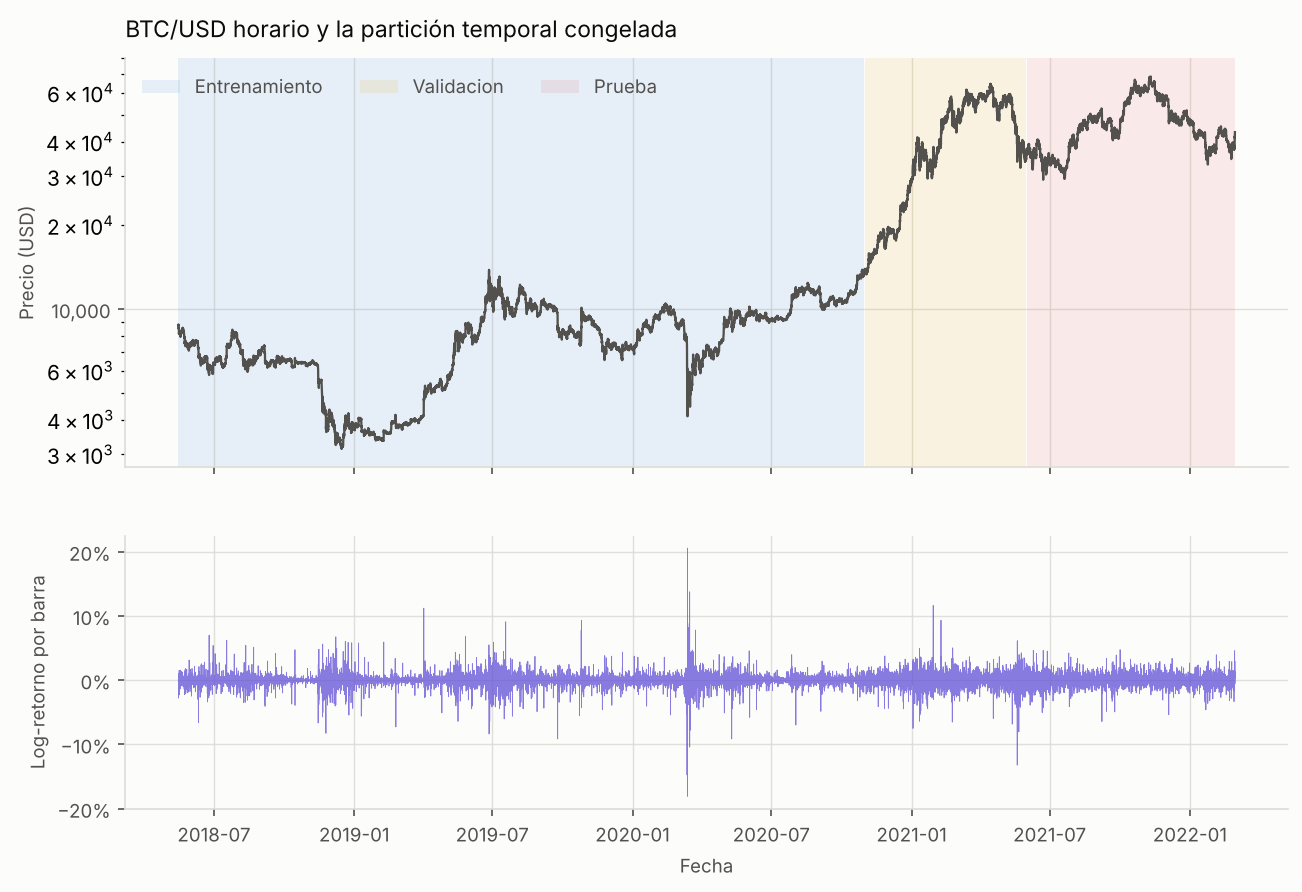

In [5]:
plots.eda_precio_y_retornos(
    precios["precio"], data.PARTICION[MERCADO],
    titulo="BTC/USD horario y la partición temporal congelada",
    etiqueta_y="Precio (USD)",
)
from IPython.display import Image
Image(str(plots.FIGURAS / "eda_serie.png"))

## 2. Estadística de los retornos — solo entrenamiento

A partir de aquí, `ent` es la única serie que se mira.

In [6]:
ent = ENT["precio"].iloc[ENT.attrs["primer_paso"]:]
r = np.log(ent).diff().dropna()
BARRAS_ANIO = data.BARRAS_POR_ANIO[MERCADO]   # 8 760: el cripto cotiza 24/7

resumen = pd.Series({
    "barras": len(r),
    "media por hora": r.mean(),
    "desviación por hora": r.std(),
    "volatilidad anualizada": r.std() * np.sqrt(BARRAS_ANIO),
    "retorno anualizado": np.expm1(r.mean() * BARRAS_ANIO),
    "asimetría": r.skew(),
    "curtosis (exceso)": r.kurt(),
    "mínimo": r.min(),
    "máximo": r.max(),
    "horas con |r| > 2 %": (r.abs() > 0.02).sum(),
})
resumen

barras                   20,874.0000
media por hora                0.0000
desviación por hora           0.0077
volatilidad anualizada        0.7247
retorno anualizado            0.3651
asimetría                    -0.1014
curtosis (exceso)            75.4385
mínimo                       -0.1809
máximo                        0.2055
horas con |r| > 2 %         532.0000
dtype: float64

Tres hechos que condicionan todo el diseño:

1. **La curtosis es enorme.** Una normal tiene exceso 0. Los eventos extremos no
   son anomalías a descartar: son una fracción material del riesgo.
2. **La media por barra es minúscula frente a la desviación.** La razón
   señal/ruido por hora es del orden de 0.01. Un costo de 10 bps por operación
   es, en esa escala, **enorme**: equivale al retorno esperado de más de cien
   horas. Esto no es un detalle de implementación, es el núcleo del problema —
   y en datos horarios pesa mucho más que en datos diarios.
3. La volatilidad anualizada ronda el 70-100 %, entre dos y tres veces la de una
   acción típica. El activo es el problema, no solo la serie.

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(r, bins=160, color="#2a78d6", alpha=0.85)
axes[0].set_yscale("log")
axes[0].set_title("Distribución de log-retornos horarios (eje y log)", loc="left")

from scipy import stats
stats.probplot(r, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico cuantil-cuantil contra la normal", loc="left")
axes[1].get_lines()[0].set_color("#2a78d6")
axes[1].get_lines()[0].set_markersize(2)
axes[1].get_lines()[1].set_color("#eb6834")

rezagos = range(1, 49)
acf_r = [r.autocorr(k) for k in rezagos]
acf_abs = [r.abs().autocorr(k) for k in rezagos]
axes[2].plot(rezagos, acf_r, color="#2a78d6", lw=2, label="r")
axes[2].plot(rezagos, acf_abs, color="#eb6834", lw=2, label="|r|")
axes[2].axhline(0, color="#52514e", lw=0.8)
axes[2].axhline(2/np.sqrt(len(r)), color="#52514e", lw=0.8, ls=":")
axes[2].set_title("Autocorrelación hasta 48 horas", loc="left")
axes[2].set_xlabel("rezago (horas)")
axes[2].legend(frameon=False)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.set_facecolor("#fcfcfb")
plt.tight_layout()
plt.show()

In [8]:
print(f"autocorrelación de r   a 1 h: {r.autocorr(1):+.4f}   a 24 h: {r.autocorr(24):+.4f}")
print(f"autocorrelación de |r| a 1 h: {r.abs().autocorr(1):+.4f}   a 24 h: {r.abs().autocorr(24):+.4f}")
print(f"banda de ruido aproximada (2/√n): ±{2/np.sqrt(len(r)):.4f}")

autocorrelación de r   a 1 h: -0.0365   a 24 h: -0.0454
autocorrelación de |r| a 1 h: +0.2898   a 24 h: +0.1561
banda de ruido aproximada (2/√n): ±0.0138


El panel de la derecha es el que justifica que haya algo que aprender — y
también lo que no:

- La autocorrelación de **r** a una hora es **−0.037**, fuera de la banda de
  ruido (±0.014). No es cero: hay una reversión a la media de muy corto plazo,
  el efecto de microestructura clásico. Pero su tamaño económico es otra cosa, y
  la celda siguiente lo calcula.
- La autocorrelación de **|r|** es **+0.29 a una hora** y sigue en +0.16 un día
  después. La **volatilidad sí es predecible**, y con holgura. Eso es lo que un
  agente de exposición puede explotar: no «¿sube o baja?», sino «¿cuánto riesgo
  hay ahora?».

Esto decide el diseño del estado: los indicadores de volatilidad (`vol_corta`,
`razon_vol`) tienen justificación empírica directa; los de momentum están porque
la literatura documenta persistencia de tendencia en cripto, no porque la
autocorrelación a una hora la respalde.

In [9]:
# ¿Alcanza la reversión a una hora para pagar las comisiones?
rho = r.autocorr(1)
ventaja = abs(rho) * r.std()          # ganancia esperada por operación
costo_ida_vuelta = 2 * 0.0010         # entrar y salir, 10 bps cada vez
print(f"autocorrelación a 1 h          : {rho:+.4f}")
print(f"ventaja esperada por operación : {100*ventaja:.4f} %  (|rho| x sigma)")
print(f"costo de ida y vuelta          : {100*costo_ida_vuelta:.4f} %")
print(f"razón costo / ventaja          : {costo_ida_vuelta/ventaja:.1f}x")
print()
print(f"La señal existe y es estadísticamente real. Es {costo_ida_vuelta/ventaja:.0f} veces")
print("más pequeña que el costo de usarla. Ese es el problema del proyecto en una línea.")

autocorrelación a 1 h          : -0.0365
ventaja esperada por operación : 0.0283 %  (|rho| x sigma)
costo de ida y vuelta          : 0.2000 %
razón costo / ventaja          : 7.1x

La señal existe y es estadísticamente real. Es 7 veces
más pequeña que el costo de usarla. Ese es el problema del proyecto en una línea.


### 2.1 Períodos de alta y baja volatilidad

El enunciado pide identificarlos, y en este proyecto no es un requisito de
forma: la volatilidad es la única magnitud predecible de la serie, así que de
aquí sale la justificación de `vol_corta` y `razon_vol`.

In [10]:
vol_movil = r.rolling(24 * 7).std() * np.sqrt(BARRAS_ANIO)
umbral_alto, umbral_bajo = vol_movil.quantile(0.75), vol_movil.quantile(0.25)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(vol_movil.index, vol_movil.to_numpy(), color="#6250d6", lw=1.2)
ax.axhline(umbral_alto, color="#e34948", lw=1, ls="--", label=f"cuartil alto ({umbral_alto:.0%})")
ax.axhline(umbral_bajo, color="#1baf7a", lw=1, ls="--", label=f"cuartil bajo ({umbral_bajo:.0%})")
ax.fill_between(vol_movil.index, umbral_alto, vol_movil.to_numpy(),
                where=(vol_movil > umbral_alto).to_numpy(), color="#e34948", alpha=0.18, lw=0)
ax.set_title("Volatilidad anualizada móvil de 7 días (tramo de entrenamiento)", loc="left")
ax.set_ylabel("Volatilidad anualizada"); ax.grid(alpha=0.25); ax.set_facecolor("#fcfcfb")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

print(f"volatilidad anualizada  mínima {vol_movil.min():.0%}   mediana {vol_movil.median():.0%}   máxima {vol_movil.max():.0%}")
print(f"razón entre el cuartil alto y el bajo: {umbral_alto/umbral_bajo:.1f}x")
print()
alto = vol_movil > umbral_alto
cambios = (alto != alto.shift()).cumsum()
rachas = alto.groupby(cambios).agg(['first', 'size'])
rachas_altas = rachas[rachas['first']]['size']
print(f"episodios de alta volatilidad: {len(rachas_altas)}   duración mediana {rachas_altas.median():.0f} horas "
      f"({rachas_altas.median()/24:.1f} días)   más largo {rachas_altas.max()/24:.0f} días")
print()
print("La volatilidad alta llega en rachas de días, no de horas: por eso un indicador")
print("de régimen calculado sobre 24 h frente a 720 h tiene información que usar.")

volatilidad anualizada  mínima 13%   mediana 55%   máxima 348%
razón entre el cuartil alto y el bajo: 1.9x

episodios de alta volatilidad: 30   duración mediana 128 horas (5.3 días)   más largo 34 días

La volatilidad alta llega en rachas de días, no de horas: por eso un indicador
de régimen calculado sobre 24 h frente a 720 h tiene información que usar.


### 2.2 Tendencias y períodos de caída

El drawdown histórico muestra de qué tamaño y de qué duración son las caídas que
el agente tendrá que atravesar. Es también la motivación de la recompensa con
penalización por drawdown que se compara en el informe.

In [11]:
precio_ent = ent
pico = precio_ent.cummax()
dd = precio_ent / pico - 1.0

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, height_ratios=[1.4, 1])
a1.plot(precio_ent.index, precio_ent.to_numpy(), color="#52514e", lw=1.1)
a1.plot(pico.index, pico.to_numpy(), color="#eb6834", lw=1, ls="--", label="máximo histórico")
a1.set_yscale("log"); a1.set_title("Precio y máximo histórico (entrenamiento)", loc="left")
a1.set_ylabel("USD (escala log)"); a1.legend(frameon=False)
a2.fill_between(dd.index, 0, dd.to_numpy(), color="#e34948", alpha=0.5, lw=0)
a2.set_ylabel("Drawdown"); a2.set_xlabel("Fecha")
for ax in (a1, a2):
    ax.grid(alpha=0.25); ax.set_facecolor("#fcfcfb")
plt.tight_layout(); plt.show()

print(f"drawdown máximo del activo en entrenamiento: {dd.min():.1%}")
print(f"horas por debajo del −20 % del máximo: {(dd < -0.20).mean():.1%} del tramo")
print(f"horas por debajo del −50 % del máximo: {(dd < -0.50).mean():.1%} del tramo")
bajo_agua = (dd < -0.01)
cambios = (bajo_agua != bajo_agua.shift()).cumsum()
rachas = bajo_agua.groupby(cambios).agg(['first', 'size'])
largas = rachas[rachas['first']]['size']
print(f"racha más larga por debajo del máximo: {largas.max()/24:.0f} días")
print()
print("Comprar y mantener en este tramo implicaba aguantar una caída del "
      f"{abs(dd.min()):.0%} y pasar {(dd < -0.20).mean():.0%} del tiempo más de un 20 % por debajo del máximo.")

drawdown máximo del activo en entrenamiento: -70.3%
horas por debajo del −20 % del máximo: 78.0% del tramo
horas por debajo del −50 % del máximo: 18.5% del tramo
racha más larga por debajo del máximo: 489 días

Comprar y mantener en este tramo implicaba aguantar una caída del 70% y pasar 78% del tiempo más de un 20 % por debajo del máximo.


### 2.3 Volumen — está disponible, y tiene un defecto

El enunciado pide analizar el volumen «si está disponible». Está, y el análisis
devuelve algo más interesante que una estadística descriptiva: **el archivo trae
las dos columnas de volumen intercambiadas durante el 60 % de la serie**.

La identidad que tiene que cumplirse siempre es `Volume USD = volume × precio`.
La celda siguiente la evalúa sobre el archivo **crudo**, sin la corrección que
aplica el cargador, para que el defecto se vea.

In [12]:
crudo = pd.read_csv(data.DATOS / "btc_crudo.csv", parse_dates=["date"]).sort_values("date")
razon_cruda = crudo["Volume USD"] / crudo["volume"].replace(0, np.nan)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(crudo["date"], razon_cruda, color="#e34948", lw=0.8, label="Volume USD / volume (archivo crudo)")
ax.plot(crudo["date"], crudo["close"], color="#2a78d6", lw=1.2, label="precio de cierre")
ax.set_yscale("log"); ax.set_title("La identidad Volume USD = volume x precio, sobre el archivo sin corregir", loc="left")
ax.set_ylabel("escala log"); ax.grid(alpha=0.25); ax.set_facecolor("#fcfcfb"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

print("Si las columnas estuvieran bien, la curva roja estaría encima de la azul en toda la serie.")
print("Antes de oct-2020 está varios órdenes de magnitud por debajo: las columnas están al revés.")

Si las columnas estuvieran bien, la curva roja estaría encima de la azul en toda la serie.
Antes de oct-2020 está varios órdenes de magnitud por debajo: las columnas están al revés.


In [13]:
# El volumen ya corregido por el cargador, y su relación con la volatilidad.
vol_btc = precios.loc[ent.index, "volume"]
log_vol = np.log(vol_btc.replace(0, np.nan)).dropna()
abs_r = r.abs().reindex(log_vol.index)

print(f"volumen horario (BTC)  mediana {vol_btc.median():.1f}   p95 {vol_btc.quantile(.95):.1f}")
print(f"correlación de Spearman entre log(volumen) y |retorno|: {log_vol.corr(abs_r, method='spearman'):+.3f}")
print()
print("El volumen y la magnitud del movimiento van juntos, como es esperable. Aun así")
print("el volumen NO entra en el estado del agente: se dejó fuera a propósito para que")
print("el estado sea idéntico en los dos mercados del informe (BTC y Brent) y las")
print("conclusiones no dependan de que uno tenga información que el otro no tiene.")

volumen horario (BTC)  mediana 205.8   p95 1078.1
correlación de Spearman entre log(volumen) y |retorno|: +0.493

El volumen y la magnitud del movimiento van juntos, como es esperable. Aun así
el volumen NO entra en el estado del agente: se dejó fuera a propósito para que
el estado sea idéntico en los dos mercados del informe (BTC y Brent) y las
conclusiones no dependan de que uno tenga información que el otro no tiene.


## 3. Los indicadores del estado

Diez señales causales y adimensionales, más la exposición vigente: once
componentes. Las ventanas son **horarias** (1 h / 1 día / 1 semana / 1 mes), no
las diarias del Brent — «21 barras» significa un mes en datos diarios y menos de
un día en horarios.

In [14]:
V = mercado.ventanas
print(f"{V.nombre}: ret {V.ret_corto} y {V.ret_medio} · vol {V.vol_corta} vs {V.vol_larga} · "
      f"sma {V.sma_corta} y {V.sma_larga} · rsi {V.rsi} · larga {V.larga} (calentamiento)")
ind = features.construir(ENT["precio"], V).iloc[ENT.attrs["primer_paso"]:]
ind.describe().T[["mean", "std", "min", "50%", "max"]]

horario: ret 24 y 168 · vol 24 vs 720 · sma 24 y 168 · rsi 14 · larga 720 (calentamiento)


,mean,std,min,50%,max
ret_1,0.0000,0.0077,-0.1809,0.0001,0.2055
ret_corto,0.0009,0.0371,-0.6296,0.0010,0.3049
ret_medio,0.0050,0.0995,-0.7865,0.0034,0.4148
vol_corta,0.0060,0.0049,0.0006,0.0047,0.0792
razon_vol,-0.2998,0.5337,-1.8875,-0.3290,1.6338
dist_sma_corta,0.0004,0.0204,-0.4184,0.0005,0.2271
dist_sma_larga,0.0027,0.0561,-0.6682,0.0024,0.2609
rsi,0.0079,0.1257,-0.4561,0.0077,0.4744
drawdown,-0.1330,0.1279,-0.9356,-0.0917,0.0000
pos_rango,0.0162,0.2969,-0.5000,0.0086,0.5000


In [15]:
corr = ind.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=9)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > 0.55 else "#0b0b0b")
ax.set_title("Correlación de Spearman entre indicadores (entrenamiento)", loc="left", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

Hay redundancia visible y se conserva a propósito. En una regresión la
colinealidad inflaría las varianzas de los coeficientes; en una red que solo
tiene que aproximar Q(s,·) el costo de dos entradas correlacionadas es
despreciable, y eliminarlas a mano sería una decisión tomada sobre el conjunto
de entrenamiento que no mejora nada. Lo que sí importa es que **en conjunto
estos once indicadores identifican de forma casi única cada barra**, y eso es lo
que permite memorizar.

In [16]:
# ¿Cuánto identifica el estado a la barra? Vecino más cercano en el espacio
# normalizado: si el vecino más cercano es casi siempre la barra de al lado,
# el estado es esencialmente un reloj.
esc = features.Escalador.ajustar(features.construir(ENT["precio"], V), V)
Z = esc.aplicar(features.construir(ENT["precio"], V))[ENT.attrs["primer_paso"]:]

from scipy.spatial import cKDTree
arbol = cKDTree(Z)
dist, idx = arbol.query(Z, k=2)
d1, vecino = dist[:, 1], idx[:, 1]
cerca = np.abs(vecino - np.arange(len(Z))) <= 3
print(f"dimensiones del estado: {Z.shape[1]}   barras: {len(Z):,}")
print(f"distancia mediana al vecino más cercano: {np.median(d1):.4f}")
print(f"el vecino más cercano está a ≤ 3 barras en el tiempo en {100*cerca.mean():.1f} % de los casos")
print(f"(al azar cabría esperar ≈ {100*6/len(Z):.3f} %)")

dimensiones del estado: 10   barras: 20,875
distancia mediana al vecino más cercano: 0.3086
el vecino más cercano está a ≤ 3 barras en el tiempo en 63.0 % de los casos
(al azar cabría esperar ≈ 0.029 %)


Ese último número es el diagnóstico central del proyecto. El estado no es un
identificador perfecto de la fecha, pero la localiza en una vecindad temporal
estrecha — órdenes de magnitud por encima de lo que daría el azar. Y eso basta:
una red con suficiente capacidad aprende una tabla de consulta aproximada
«tramo del calendario → acción».

Es exactamente lo que se observa en la fase 1 de los experimentos, y la razón
por la que el entrenamiento final se hace sobre trayectorias remuestreadas por
bloques.

## 4. Regímenes y el desplazamiento entre tramos

Esta es la única tabla del notebook que mira validación y prueba. Está aquí para
documentar que los tres tramos no vienen de la misma distribución, y no informó
ninguna decisión de diseño.

In [17]:
filas = {}
for tramo, (desde, hasta) in data.PARTICION[MERCADO].items():
    p = precios.loc[desde:hasta, "precio"]
    rr = np.log(p).diff().dropna()
    filas[tramo] = {
        "barras": len(p),
        "vol. anualizada": rr.std() * np.sqrt(BARRAS_ANIO),
        "curtosis": rr.kurt(),
        "asimetría": rr.skew(),
        "peor hora": rr.min(),
        "precio inicial": p.iloc[0],
        "precio final": p.iloc[-1],
        "retorno del tramo": p.iloc[-1] / p.iloc[0] - 1,
    }
pd.DataFrame(filas).T

,barras,vol. anualizada,curtosis,asimetría,peor hora,precio inicial,precio final,retorno del tramo
entrenamiento,"21,618.0000",0.7207,74.7786,-0.1334,-0.1809,"8,740.9900","13,816.0800",0.5806
validacion,"5,088.0000",0.9861,13.6041,-0.4795,-0.1323,"13,733.8400","37,341.4100",1.7189
prueba,"6,553.0000",0.7009,6.4525,-0.1177,-0.0645,"37,820.9400","43,312.2700",0.1452


Los tres tramos son tres mercados distintos:

- **Entrenamiento** (jun-2018 → oct-2020): el invierno cripto y la recuperación.
- **Validación** (nov-2020 → may-2021): el mercado alcista de 2021, +160 % en
  siete meses con volatilidad cercana al 100 % anual. Seleccionar modelo aquí
  **premia estar invertido**, y eso es un sesgo que hay que tener presente al
  leer los resultados.
- **Prueba** (jun-2021 → mar-2022): un viaje de ida y vuelta — de 37 800 a
  69 000 USD y de vuelta a 43 000 — que termina **+14 %**. Comprar y mantener
  deja de ser imbatible: una política de exposición con buen sentido del régimen
  tendría mucho que ganar aquí.

Que la línea base sea batible es lo que hace que el período de prueba sea una
prueba de verdad y no un trámite.

## 5. El costo de operar, cuantificado antes de entrenar

Con 10 bps por cambio de exposición y 8 760 barras al año, una política que
decida cada hora y cambie la mitad de las veces paga **más de 4 veces su capital
al año** en comisiones. Esta cuenta, hecha antes de entrenar, es la que motiva la
fase 6 (¿cada cuánto conviene decidir?).

In [18]:
for cada, nombre in [(1, "cada hora"), (24, "cada día"), (168, "cada semana")]:
    decisiones = BARRAS_ANIO / cada
    for p_cambio, etiqueta in [(0.5, "cambia 50 % de las veces"), (1.0, "cambia siempre")]:
        costo = decisiones * p_cambio * 0.0010
        print(f"decidir {nombre:12s} · {etiqueta:26s} → {decisiones*p_cambio:7.0f} operaciones/año "
              f"= {100*costo:7.1f} % del capital al año en costos")
    print()
print("Para referencia, el retorno anualizado del BTC en el tramo de entrenamiento")
print(f"fue del {100*np.expm1(r.mean()*BARRAS_ANIO):.0f} %.")

decidir cada hora    · cambia 50 % de las veces   →    4380 operaciones/año =   438.0 % del capital al año en costos
decidir cada hora    · cambia siempre             →    8760 operaciones/año =   876.0 % del capital al año en costos

decidir cada día     · cambia 50 % de las veces   →     182 operaciones/año =    18.2 % del capital al año en costos
decidir cada día     · cambia siempre             →     365 operaciones/año =    36.5 % del capital al año en costos

decidir cada semana  · cambia 50 % de las veces   →      26 operaciones/año =     2.6 % del capital al año en costos
decidir cada semana  · cambia siempre             →      52 operaciones/año =     5.2 % del capital al año en costos

Para referencia, el retorno anualizado del BTC en el tramo de entrenamiento
fue del 37 %.


## 6. Qué se lleva el diseño de este análisis

| Hallazgo | Consecuencia de diseño |
|---|---|
| Autocorrelación de `r` nula, de `\|r\|` persistente durante días | El estado lleva indicadores de volatilidad; el agente decide exposición, no dirección |
| Curtosis ≫ 0 | Se prueba una recompensa con penalización de drawdown, no solo retorno |
| Señal/ruido por barra ≈ 0.01 con costo de 10 bps | La rotación se reporta como métrica de primer orden, y la frecuencia de decisión se convierte en una decisión de diseño (fase 6) |
| El estado identifica la barra | El entrenamiento final usa remuestreo por bloques; sin eso el agente memoriza |
| Validación alcista, prueba de ida y vuelta | Se declara el sesgo de selección hacia «estar invertido» antes de leer el test |
| Columnas de volumen intercambiadas | El estado se construye solo con precio; la corrección queda en el cargador |